The intuition behind tree-based outlier detection is straightforward:

Outliers are rare and different. Therefore, they are easy to isolate and get separated near the top of the tree with very few splits.

Normal points are clustered together. They require many random splits deep down the tree to isolate them individually.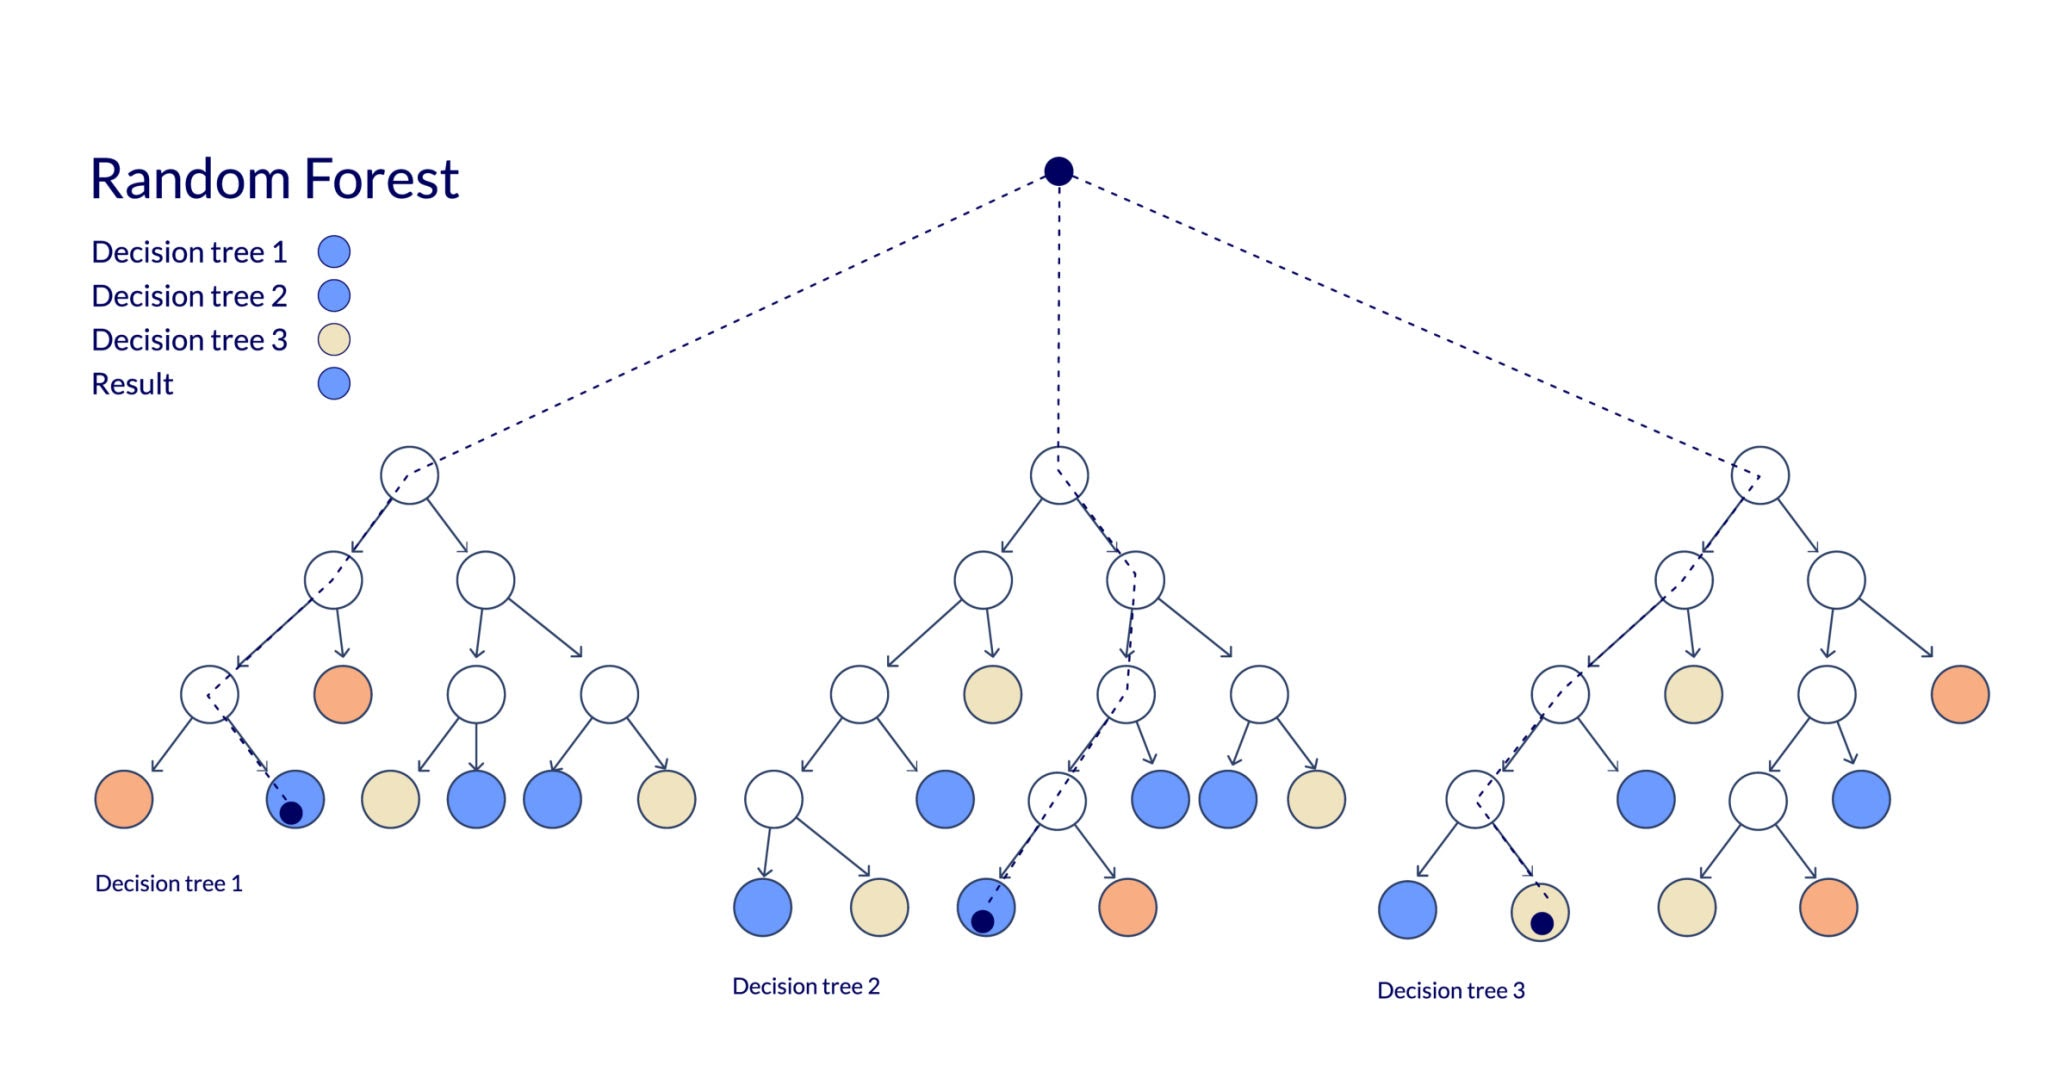

How the Algorithm Thinks:Pick a Random Feature: (e.g., Price).

Pick a Random Split Value: Choose a value between the minimum and maximum of that feature.

Split the Data: Divide the dataset into left and right branches.Repeat: Keep randomly splitting until every point is isolated in its own leaf node.

Score the Point:Short path length (1 or 2 splits) $\rightarrow$ Outlier.

Long path length (many splits) $\rightarrow$ Normal data point.

How the Algorithm Thinks:Pick a Random Feature: (e.g., Price).

Pick a Random Split Value: Choose a value between the minimum and maximum of that feature.

Split the Data: Divide the dataset into left and right branches.

Repeat: Keep randomly splitting until every point is isolated in its own leaf node.

Score the Point:Short path length (1 or 2 splits) $\rightarrow$ Outlier.

Long path length (many splits) $\rightarrow$ Normal data point.

In [ ]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# 1. Load data and select numerical features
df = pd.read_csv("used_cars_data.csv")
X = df[["Kilometers_Driven", "Price"]].dropna()

# 2. Initialize and fit the Isolation Forest model
# contamination=0.05 means we expect roughly 5% outliers
model = IsolationForest(contamination=0.05, random_state=42)
X["anomaly_label"] = model.fit_predict(X)

# 3. Filter outliers (-1 indicates an outlier, 1 indicates normal data)
outliers = X[X["anomaly_label"] == -1]

print(outliers)

      Kilometers_Driven   Price  anomaly_label
29               262000    4.00             -1
38                85000   28.00             -1
64               178000    2.50             -1
77               230000    4.50             -1
134               13372   54.00             -1
...                 ...     ...            ...
5919               8000  100.00             -1
5927              29091   45.52             -1
5946              16000   48.00             -1
5957             186679    1.76             -1
6008              40000   45.00             -1

[301 rows x 3 columns]


In [ ]:
model = IsolationForest(contamination=0.05, random_state=42)

contamination: The proportion of outliers you expect in your dataset (e.g., 0.05 = top 5%).

random_state: Ensures you get the exact same tree splits every time you run the code.

In [ ]:
X["anomaly_label"] = model.fit_predict(X)

fit_predict() builds the ensemble of random trees and assigns a label to each row:

1: Normal observation.

-1: Outlier (isolated quickly near the top of the trees).